# SuspiciousLogin v2.0 — Public Results Analysis

This notebook reproduces the **descriptive results of Article 1 using only the public release** of SuspiciousLogin v2.0.

## Scope

The notebook requires only `suspicious_logins_public_v2.csv` and does **not** access the restricted dataset, raw logs, institutional identifiers, exact timestamps, the institutional `network_pseudo_id`, HMAC keys, or administrative credentials.

It reproduces public descriptive results related to dataset size, actor activity, provider-generated suspiciousness, authentication characteristics, geographic distribution, monthly coverage, and missingness of the **42 public attributes**.

`actor_network_id` is public and actor-scoped; it does not provide a cross-actor network join key. Institutional characterization remains excluded because `institution_pseudo_id` is restricted.


## 1. Environment and public dataset

In [2]:
from pathlib import Path
import os
import json
import math
import hashlib

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

EXPECTED_PUBLIC = [
    "event_id",
    "actor_pseudo_id",
    "event_time_hour_utc",
    "event_hour",
    "day_of_week",
    "month",
    "is_weekend",
    "prior_event_count",
    "hours_since_last_login",
    "hours_since_first_observed_login",
    "logins_24h",
    "logins_7d",
    "logins_30d",
    "login_rate_30d",
    "active_days_30d",
    "actor_network_id",
    "ip_version",
    "is_new_ip",
    "ip_changed",
    "distinct_networks_24h",
    "distinct_networks_7d",
    "distinct_networks_30d",
    "networks_seen_to_date",
    "ip_country",
    "continent",
    "is_new_country",
    "country_changed",
    "is_new_continent",
    "continent_changed",
    "distinct_countries_24h",
    "distinct_countries_7d",
    "distinct_countries_30d",
    "distinct_countries_to_date",
    "login_type",
    "login_challenge_method",
    "is_new_login_type",
    "login_type_changed",
    "is_new_challenge",
    "challenge_changed",
    "distinct_login_types_30d",
    "distinct_challenges_30d",
    "provider_suspicious",
]

# Public repository default. You may override it with:
# SUSPICIOUSLOGIN_PUBLIC_CSV=/path/to/file.csv
configured = os.getenv("SUSPICIOUSLOGIN_PUBLIC_CSV")
candidates = []
if configured:
    candidates.append(Path(configured))

candidates += [
    Path("data/suspicious_logins_public_v2.csv"),
    Path("../data/suspicious_logins_public_v2.csv"),
    Path("suspicious_logins_public_v2.csv"),
]

PUBLIC_FILE = next((p for p in candidates if p.exists()), None)
if PUBLIC_FILE is None:
    raise FileNotFoundError(
        "Public CSV not found. Place suspicious_logins_public_v2.csv in data/ "
        "or define SUSPICIOUSLOGIN_PUBLIC_CSV."
    )

OUTPUT_DIR = Path("outputs/article_one_results")
FIGURE_DIR = OUTPUT_DIR / "figures"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

public = pd.read_csv(PUBLIC_FILE, low_memory=False)

if list(public.columns) != EXPECTED_PUBLIC:
    raise ValueError(
        f"Expected exactly 42 public attributes in the v2.0 schema; found {len(public.columns)}.\n"
        f"Columns found: {list(public.columns)}"
    )

public["event_time_hour_utc"] = pd.to_datetime(
    public["event_time_hour_utc"], utc=True, errors="raise"
)
public["provider_suspicious"] = pd.to_numeric(
    public["provider_suspicious"], errors="raise"
).astype(int)

with open(PUBLIC_FILE, "rb") as f:
    public_sha256 = hashlib.sha256(f.read()).hexdigest()

print(f"Public file: {PUBLIC_FILE.resolve()}")
print(f"Rows: {len(public):,}")
print(f"Columns: {len(public.columns)}")
print(f"SHA-256: {public_sha256}")

Public file: E:\Developer\suspiciouslogin\public\data\suspicious_logins_public_v2.csv
Rows: 73,526
Columns: 42
SHA-256: 47be2f74f1c1db3f1dbed2cf4343ca099de9a1ca59373c1b5eff2686688073ec


## 2. Dataset overview

In [3]:
n_events = len(public)
n_actors = public["actor_pseudo_id"].nunique()
flagged = int(public["provider_suspicious"].sum())
not_flagged = int((public["provider_suspicious"] == 0).sum())
flagged_pct = flagged / n_events * 100

public_time_min = public["event_time_hour_utc"].min()
public_time_max = public["event_time_hour_utc"].max()

overview = pd.DataFrame([
    ["Authentication events", n_events],
    ["Pseudonymized actors", n_actors],
    ["Public attributes", len(public.columns)],
    ["Provider flagged events", flagged],
    ["Provider not-flagged events", not_flagged],
    ["Provider flagged proportion (%)", flagged_pct],
    ["Public time coverage start (hour UTC)", public_time_min.isoformat()],
    ["Public time coverage end (hour UTC)", public_time_max.isoformat()],
], columns=["metric", "value"])

overview.to_csv(OUTPUT_DIR / "dataset_overview.csv", index=False)
overview

,metric,value
0,Authentication events,73526
1,Pseudonymized actors,12190
2,Public attributes,42
3,Provider flagged events,7196
4,Provider not-flagged events,66330
5,Provider flagged proportion (%),9.7870
6,Public time coverage start (hour UTC),2025-12-19T19:00:00+00:00
7,Public time coverage end (hour UTC),2026-08-12T16:00:00+00:00


The public timestamp is generalized to the hour. Therefore, the temporal limits above describe the **publicly observable coverage**, not the exact second/millisecond boundaries retained in the restricted schema. Network, country, and authentication-diversity features based on `event_time_hour_utc` can be recomputed from the public release; exact login-count windows and exact-hour intervals cannot.


## 3. Actor activity and observed history

In [4]:
def gini_coefficient(values):
    x = np.sort(np.asarray(values, dtype=float))
    if len(x) == 0 or x.sum() == 0:
        return np.nan
    n = len(x)
    return 2 * np.sum(np.arange(1, n + 1) * x) / (n * x.sum()) - (n + 1) / n

actor_counts = public["actor_pseudo_id"].value_counts()
q1, median, q3 = actor_counts.quantile([0.25, 0.50, 0.75])

n_singleton = int((actor_counts == 1).sum())
n_recurrent = int((actor_counts > 1).sum())
with_history = int((public["prior_event_count"] > 0).sum())
without_history = int((public["prior_event_count"] == 0).sum())

top_1_n = max(1, math.ceil(n_actors * 0.01))
top_10_n = max(1, math.ceil(n_actors * 0.10))

actor_summary = pd.DataFrame([
    ["Actors with one event", n_singleton, "actors", n_singleton / n_actors * 100],
    ["Actors with recurrent events", n_recurrent, "actors", n_recurrent / n_actors * 100],
    ["Events with prior observed history", with_history, "events", with_history / n_events * 100],
    ["Events without prior observed history", without_history, "events", without_history / n_events * 100],

    ["Actor events Q1", float(q1), "events/actor", None],
    ["Actor events median", float(median), "events/actor", None],
    ["Actor events Q3", float(q3), "events/actor", None],
    ["Actor events maximum", int(actor_counts.max()), "events/actor", None],

    ["Activity Gini coefficient", gini_coefficient(actor_counts), "index", None],

    ["Event share of top 1% actors",
     actor_counts.nlargest(top_1_n).sum(),
     "events",
     actor_counts.nlargest(top_1_n).sum() / n_events * 100],

    ["Event share of top 10% actors",
     actor_counts.nlargest(top_10_n).sum(),
     "events",
     actor_counts.nlargest(top_10_n).sum() / n_events * 100],

], columns=["metric", "value", "unit", "percent"])

actor_summary_display = actor_summary.copy()

actor_summary_display["percent"] = (
    actor_summary_display["percent"]
    .map(lambda x: f"{x:.4f}" if pd.notna(x) else "—")
)
actor_summary_display


,metric,value,unit,percent
0,Actors with one event,347.0000,actors,2.8466
1,Actors with recurrent events,"11,843.0000",actors,97.1534
2,Events with prior observed history,"61,336.0000",events,83.4208
3,Events without prior observed history,"12,190.0000",events,16.5792
4,Actor events Q1,3.0000,events/actor,—
5,Actor events median,3.0000,events/actor,—
6,Actor events Q3,4.0000,events/actor,—
7,Actor events maximum,"1,847.0000",events/actor,—
8,Activity Gini coefficient,0.5376,index,—
9,Event share of top 1% actors,"22,007.0000",events,29.9309


The Gini coefficient and concentration measures are computed directly from the number of public events per `actor_pseudo_id`. No restricted field is required.

Gini coefficient: 0.537553


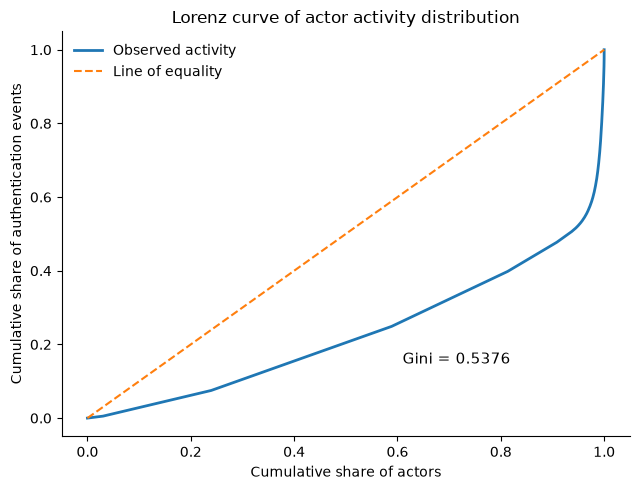

In [5]:
# ============================================================
# Lorenz curve and Gini coefficient
# ============================================================

# Sort from least active to most active actor
x = np.sort(actor_counts)

# Lorenz curve
lorenz = np.insert(np.cumsum(x) / x.sum(),0,0)
population_share = np.linspace(0,1,len(lorenz))   

# Gini coefficient
gini = gini_coefficient(actor_counts)
print(f"Gini coefficient: {gini:.6f}")

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

#sns.set_style("whitegrid")
fig, ax = plt.subplots(figsize=(6.5, 5.0))

ax.plot(population_share,lorenz,linewidth=2,label="Observed activity")
ax.plot([0, 1],[0, 1],linestyle="--",linewidth=1.5,label="Line of equality")
ax.set_xlabel("Cumulative share of actors")
ax.set_ylabel("Cumulative share of authentication events")
ax.set_title("Lorenz curve of actor activity distribution")
ax.text(0.60,0.18,f"Gini = {gini:.4f}",transform=ax.transAxes,fontsize=11)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(frameon=False,loc="upper left")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "lorenz_activity.pdf",bbox_inches="tight")
fig.savefig(FIGURE_DIR / "lorenz_activity.png",dpi=1000,bbox_inches="tight")
plt.show()

In [6]:
n_events = len(public)
n_actors = public["actor_pseudo_id"].nunique()
actor_counts_series = public["actor_pseudo_id"].value_counts()

top_1_n = max(1,math.ceil(n_actors * 0.01))
top_10_n = max(1,math.ceil(n_actors * 0.10))
top_1_events = actor_counts_series.nlargest(top_1_n).sum()
top_10_events = actor_counts_series.nlargest(top_10_n).sum()
top_1_pct = (top_1_events / n_events * 100)
top_10_pct = (top_10_events / n_events * 100)

print(f"Top 1%: {top_1_events:,} events ({top_1_pct:.4f}%)")
print(f"Top 10%: {top_10_events:,} events ({top_10_pct:.4f}%)")

Top 1%: 22,007 events (29.9309%)
Top 10%: 38,961 events (52.9894%)


## 4. Provider-generated suspiciousness signal

In [5]:
provider_distribution = (
    public["provider_suspicious"]
    .value_counts(dropna=False)
    .sort_index()
    .rename_axis("provider_suspicious")
    .reset_index(name="events")
)
provider_distribution["percent"] = provider_distribution["events"] / n_events * 100

provider_by_history = (
    public.assign(has_prior_history=(public["prior_event_count"] > 0).astype(int))
    .groupby("has_prior_history", dropna=False)["provider_suspicious"]
    .agg(events="size", provider_suspicious_1="sum", provider_suspicious_pct="mean")
    .reset_index()
)
provider_by_history["provider_suspicious_pct"] *= 100

provider_distribution.to_csv(
    OUTPUT_DIR / "provider_suspicious_distribution.csv", index=False
)
provider_by_history.to_csv(
    OUTPUT_DIR / "provider_suspicious_by_history.csv", index=False
)

print("Provider signal distribution")
display(provider_distribution)
print("Provider signal by availability of prior observed history")
display(provider_by_history)

Provider signal distribution


,provider_suspicious,events,percent
0,0,66330,90.2130
1,1,7196,9.7870


Provider signal by availability of prior observed history


,has_prior_history,events,provider_suspicious_1,provider_suspicious_pct
0,0,12190,1531,12.5595
1,1,61336,5665,9.2360


> `provider_suspicious=1` means that the successful authentication event was flagged by the provider. It is **not** treated as confirmed compromise, attack ground truth, or verified malicious activity.

## 5. Authentication characteristics

In [6]:
login_type_table = (
    public["login_type"]
    .fillna("<missing>")
    .value_counts(dropna=False)
    .rename_axis("login_type")
    .reset_index(name="events")
)
login_type_table["percent"] = login_type_table["events"] / n_events * 100

challenge_raw = (
    public["login_challenge_method"]
    .fillna("<missing>")
    .value_counts(dropna=False)
    .rename_axis("login_challenge_method")
    .reset_index(name="events")
)
challenge_raw["percent"] = challenge_raw["events"] / n_events * 100

# Optional token-level view for multi-method values separated by '|'.
challenge_tokens = (
    public["login_challenge_method"]
    .dropna()
    .astype(str)
    .str.split("|")
    .explode()
    .str.strip()
)
challenge_token_table = (
    challenge_tokens[challenge_tokens.ne("")]
    .value_counts()
    .rename_axis("challenge_token")
    .reset_index(name="occurrences")
)
challenge_token_table["percent_of_events"] = challenge_token_table["occurrences"] / n_events * 100

login_type_table.to_csv(OUTPUT_DIR / "login_type_distribution.csv", index=False)
challenge_raw.to_csv(OUTPUT_DIR / "login_challenge_method_distribution.csv", index=False)
challenge_token_table.to_csv(OUTPUT_DIR / "login_challenge_token_distribution.csv", index=False)

print("Login type")
display(login_type_table)
print("Most frequent raw challenge-method values")
display(challenge_raw.head(15))
print("Challenge-method tokens")
display(challenge_token_table.head(15))

Login type


,login_type,events,percent
0,google_password,35454,48.2197
1,reauth,27277,37.0984
2,exchange,10795,14.6819


Most frequent raw challenge-method values


,login_challenge_method,events,percent
0,password,34505,46.9290
1,none,29593,40.2483
2,authenticator_app,5550,7.5484
3,security_key,2539,3.4532
4,password|device_prompt,379,0.5155
5,password|idv_preregistered_phone,279,0.3795
6,device_prompt,185,0.2516
7,idv_preregistered_phone,163,0.2217
8,password|idv_preregistered_email,64,0.0870
9,password|passkey,52,0.0707


Challenge-method tokens


,challenge_token,occurrences,percent_of_events
0,password,35383,48.1231
1,none,29593,40.2483
2,authenticator_app,5550,7.5484
3,security_key,2539,3.4532
4,device_prompt,592,0.8052
5,idv_preregistered_phone,491,0.6678
6,idv_preregistered_email,125,0.1700
7,passkey,95,0.1292
8,idv_any_phone,24,0.0326
9,knowledge_historical_password,20,0.0272


## 6. Geographic characteristics

In [7]:
country_table = (
    public["ip_country"]
    .fillna("<missing>")
    .value_counts(dropna=False)
    .rename_axis("ip_country")
    .reset_index(name="events")
)
country_table["percent"] = country_table["events"] / n_events * 100

country_summary = pd.DataFrame({
    "known_country_values": [int(public["ip_country"].nunique(dropna=True))],
    "missing_country_events": [int(public["ip_country"].isna().sum())],
})

country_table.to_csv(OUTPUT_DIR / "country_distribution.csv", index=False)
country_summary.to_csv(OUTPUT_DIR / "country_summary.csv", index=False)

print(country_summary.to_string(index=False))
display(country_table.head(15))

 known_country_values  missing_country_events
                   23                       1


,ip_country,events,percent
0,Angola,47314,64.3500
1,Brazil,25281,34.3838
2,Portugal,484,0.6583
3,United States,107,0.1455
4,Namibia,59,0.0802
5,Germany,54,0.0734
6,Netherlands,52,0.0707
7,France,42,0.0571
8,Australia,25,0.0340
9,Poland,20,0.0272


The public CSV preserves normalized country values. Rare countries are not replaced by `Other` in the release. Any aggregation into `Other` should be performed only for a specific analysis or presentation.

## 7. Monthly public characterization

In [8]:
monthly = public.assign(
    year_month=public["event_time_hour_utc"].dt.strftime("%Y-%m")
)

monthly_table = (
    monthly.groupby("year_month", sort=True)
    .agg(
        events=("event_id", "size"),
        actors=("actor_pseudo_id", "nunique"),
        provider_suspicious_1=("provider_suspicious", "sum"),
        provider_suspicious_pct=("provider_suspicious", "mean"),
    )
    .reset_index()
)
monthly_table["provider_suspicious_pct"] *= 100

monthly_table.to_csv(OUTPUT_DIR / "monthly_characterization.csv", index=False)
monthly_table

,year_month,events,actors,provider_suspicious_1,provider_suspicious_pct
0,2025-12,1508,368,50,3.3156
1,2026-01,10393,3906,1054,10.1414
2,2026-02,9026,3729,986,10.9240
3,2026-03,9777,4100,909,9.2973
4,2026-04,10516,4208,1094,10.4032
5,2026-05,9733,4177,1018,10.4593
6,2026-06,17961,7090,2021,11.2522
7,2026-07,3172,574,42,1.3241
8,2026-08,1440,411,22,1.5278


Monthly counts describe the **coverage of the public dataset**. Because the public release does not contain `institution_pseudo_id`, this notebook does not reproduce institution-specific monthly coverage and does not interpret monthly counts as behavioral trends.

## 8. Missingness of the 42-attribute public schema


In [9]:
public_missingness = pd.DataFrame({
    "attribute": public.columns,
    "missing": [int(public[c].isna().sum()) for c in public.columns],
})
public_missingness["percent"] = public_missingness["missing"] / n_events * 100

public_missingness.to_csv(OUTPUT_DIR / "missingness_public.csv", index=False)
public_missingness[public_missingness["missing"] > 0].reset_index(drop=True)

,attribute,missing,percent
0,hours_since_last_login,12190,16.5792
1,ip_version,2,0.0027
2,ip_country,1,0.0014
3,continent,1,0.0014
4,is_new_country,1,0.0014
5,country_changed,2,0.0027
6,is_new_continent,1,0.0014
7,continent_changed,2,0.0027
8,login_challenge_method,1,0.0014
9,is_new_challenge,1,0.0014


For `hours_since_last_login`, missingness on the first observed event of each actor is structural. Other missing values should be interpreted according to the public data dictionary.

## 9. Publication-ready figures from public data

In [ ]:
# Figure 1 — Monthly number of public authentication events
fig, ax = plt.subplots(figsize=(7.2, 4.0))
ax.plot(monthly_table["year_month"], monthly_table["events"], marker="o", linewidth=1.8)
ax.set_xlabel("Month")
ax.set_ylabel("Authentication events")
ax.tick_params(axis="x", rotation=45)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="y", linestyle="--", linewidth=0.5, alpha=0.4)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "monthly_authentication_events.pdf", bbox_inches="tight")
fig.savefig(FIGURE_DIR / "monthly_authentication_events.png", dpi=600, bbox_inches="tight")
plt.show()

# Figure 2 — Login type distribution
plot_login = login_type_table.sort_values("events", ascending=True)
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.barh(plot_login["login_type"], plot_login["events"])
ax.set_xlabel("Authentication events")
ax.set_ylabel("")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="x", linestyle="--", linewidth=0.5, alpha=0.4)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "login_type_distribution.pdf", bbox_inches="tight")
fig.savefig(FIGURE_DIR / "login_type_distribution.png", dpi=600, bbox_inches="tight")
plt.show()

# Figure 3 — Most frequent raw challenge-method values
plot_challenge = challenge_raw.head(10).sort_values("events", ascending=True)
fig, ax = plt.subplots(figsize=(7.0, 4.2))
ax.barh(plot_challenge["login_challenge_method"], plot_challenge["events"])
ax.set_xlabel("Authentication events")
ax.set_ylabel("")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="x", linestyle="--", linewidth=0.5, alpha=0.4)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "login_challenge_method_top10.pdf", bbox_inches="tight")
fig.savefig(FIGURE_DIR / "login_challenge_method_top10.png", dpi=600, bbox_inches="tight")
plt.show()

# Figure 4 — Most frequent countries
plot_country = country_table.head(10).sort_values("events", ascending=True)
fig, ax = plt.subplots(figsize=(6.5, 4.2))
ax.barh(plot_country["ip_country"], plot_country["events"])
ax.set_xlabel("Authentication events")
ax.set_ylabel("")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="x", linestyle="--", linewidth=0.5, alpha=0.4)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "country_distribution_top10.pdf", bbox_inches="tight")
fig.savefig(FIGURE_DIR / "country_distribution_top10.png", dpi=600, bbox_inches="tight")
plt.show()

NameError: name 'plt' is not defined

No Lorenz/Gini figure is generated here because the manuscript already contains that visualization. The Gini statistic itself remains computed above so the reported numerical result can be reproduced from the public release.

## 10. Export a compact public statistics file

In [11]:
public_statistics = {
    "dataset_name": "SuspiciousLogin",
    "dataset_version": "2.0",
    "public_sha256": public_sha256,
    "events": int(n_events),
    "actors": int(n_actors),
    "public_attributes": int(len(public.columns)),
    "public_time_hour_min": public_time_min.isoformat(),
    "public_time_hour_max": public_time_max.isoformat(),
    "singleton_users": n_singleton,
    "recurrent_users": n_recurrent,
    "events_with_prior_history": with_history,
    "events_without_prior_history": without_history,
    "provider_suspicious_0": not_flagged,
    "provider_suspicious_1": flagged,
    "provider_suspicious_pct": float(flagged_pct),
    "actor_events_q1": float(q1),
    "actor_events_median": float(median),
    "actor_events_q3": float(q3),
    "actor_events_max": int(actor_counts.max()),
    "activity_gini": float(gini_coefficient(actor_counts)),
    "top_1pct_actor_event_share_pct": float(actor_counts.nlargest(top_1_n).sum() / n_events * 100),
    "top_10pct_actor_event_share_pct": float(actor_counts.nlargest(top_10_n).sum() / n_events * 100),
    "known_country_values": int(public["ip_country"].nunique(dropna=True)),
    "missing_country_events": int(public["ip_country"].isna().sum()),
}

stats_file = OUTPUT_DIR / "article1_public_statistics.json"
stats_file.write_text(
    json.dumps(public_statistics, ensure_ascii=False, indent=2),
    encoding="utf-8"
)

print(json.dumps(public_statistics, ensure_ascii=False, indent=2))
print(f"\nSaved: {stats_file}")

{
  "dataset_name": "SuspiciousLogin",
  "dataset_version": "2.0",
  "public_sha256": "47be2f74f1c1db3f1dbed2cf4343ca099de9a1ca59373c1b5eff2686688073ec",
  "events": 73526,
  "actors": 12190,
  "public_attributes": 42,
  "public_time_hour_min": "2025-12-19T19:00:00+00:00",
  "public_time_hour_max": "2026-08-12T16:00:00+00:00",
  "singleton_users": 347,
  "recurrent_users": 11843,
  "events_with_prior_history": 61336,
  "events_without_prior_history": 12190,
  "provider_suspicious_0": 66330,
  "provider_suspicious_1": 7196,
  "provider_suspicious_pct": 9.78701411745505,
  "actor_events_q1": 3.0,
  "actor_events_median": 3.0,
  "actor_events_q3": 4.0,
  "actor_events_max": 1847,
  "activity_gini": 0.5375532190239156,
  "top_1pct_actor_event_share_pct": 29.930908794168047,
  "top_10pct_actor_event_share_pct": 52.9894187090281,
  "known_country_values": 23,
  "missing_country_events": 1
}

Saved: outputs\article_one_results\article1_public_statistics.json


## 11. Public analysis completion

In [12]:
print("=" * 72)
print("PUBLIC RESULTS ANALYSIS: COMPLETE")
print(f"Dataset analyzed: {PUBLIC_FILE.name}")
print(f"Outputs written to: {OUTPUT_DIR.resolve()}")
print("No restricted dataset was loaded or required.")
print("=" * 72)

PUBLIC RESULTS ANALYSIS: COMPLETE
Dataset analyzed: suspicious_logins_public_v2.csv
Outputs written to: E:\Developer\suspiciouslogin\public\notebooks\outputs\article_one_results
No restricted dataset was loaded or required.
